# Faz 4 — Modelleme


In [ ]:
import pandas as pd
import numpy as np

train_df = pd.read_csv('../data/processed/train_featured.csv', parse_dates=['Date'])
test_df = pd.read_csv('../data/processed/test_featured.csv', parse_dates=['Date'])
print('Train:', train_df.shape, ' Test:', test_df.shape)


In [ ]:
import numpy as np

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def mape(y_true, y_pred):
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

In [ ]:
test_eval = test_df[(test_df['Open'] == 1) & (test_df['Sales_lag_7'].notnull())].copy()

baseline_rmse = rmse(test_eval['Sales'].values, test_eval['Sales_lag_7'].values)
baseline_mape = mape(test_eval['Sales'].values, test_eval['Sales_lag_7'].values)

print('Baseline RMSE:', round(baseline_rmse, 2))
print('Baseline MAPE:', round(baseline_mape, 2), '%')

Baseline RMSE: 2809.07
Baseline MAPE: 31.82 %


In [ ]:
feature_cols = [
    'Store', 'DayOfWeek', 'Promo', 'SchoolHoliday', 'StateHoliday_enc',
    'StoreType_enc', 'Assortment_enc', 'CompetitionDistance', 'CompetitionOpen',
    'Promo2', 'Year', 'Month', 'Day', 'WeekOfYear', 'Quarter', 'IsWeekend', 'DaysToChristmas',
    'Sales_lag_7', 'Sales_lag_14', 'Sales_lag_28',
    'Sales_rolling_mean_7', 'Sales_rolling_std_7',
    'Sales_rolling_mean_14', 'Sales_rolling_std_14',
    'Sales_rolling_mean_30', 'Sales_rolling_std_30'
]

train_model_df = train_df.dropna(subset=feature_cols)

X_train = train_model_df[feature_cols]
y_train = train_model_df['Sales']

X_test = test_eval[feature_cols]
y_test = test_eval['Sales']

print(X_train.shape, X_test.shape)

(768932, 26) (41396, 26)


In [ ]:
from xgboost import XGBRegressor

model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

model.fit(X_train, y_train)

preds = model.predict(X_test)

xgb_rmse = rmse(y_test.values, preds)
xgb_mape = mape(y_test.values, preds)

print('XGBoost RMSE:', round(xgb_rmse, 2))
print('XGBoost MAPE:', round(xgb_mape, 2), '%')
print()
print('Baseline RMSE:', round(baseline_rmse, 2))
print('Baseline MAPE:', round(baseline_mape, 2), '%')

XGBoost RMSE: 888.36
XGBoost MAPE: 9.12 %

Baseline RMSE: 2809.07
Baseline MAPE: 31.82 %


In [ ]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=3)
cv_rmse_scores = []
cv_mape_scores = []

X_train_full = train_model_df[feature_cols].reset_index(drop=True)
y_train_full = train_model_df['Sales'].reset_index(drop=True)

for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train_full)):
    X_tr, X_val = X_train_full.iloc[tr_idx], X_train_full.iloc[val_idx]
    y_tr, y_val = y_train_full.iloc[tr_idx], y_train_full.iloc[val_idx]

    cv_model = XGBRegressor(
        n_estimators=500,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        early_stopping_rounds=50,
        eval_metric='rmse'
    )
    # early stopping burada gerçek bir doğrulama setini (X_val, y_val) izliyor, train'i değil
    cv_model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)

    val_preds = cv_model.predict(X_val)
    fold_rmse = rmse(y_val.values, val_preds)
    fold_mape = mape(y_val.values, val_preds)
    cv_rmse_scores.append(fold_rmse)
    cv_mape_scores.append(fold_mape)
    print(f'Fold {fold+1} -> RMSE: {round(fold_rmse,2)}, MAPE: {round(fold_mape,2)}%')

print()
print(f'CV RMSE ortalaması: {round(np.mean(cv_rmse_scores),2)} (+/- {round(np.std(cv_rmse_scores),2)})')
print(f'CV MAPE ortalaması: {round(np.mean(cv_mape_scores),2)}% (+/- {round(np.std(cv_mape_scores),2)})')

Fold 1 -> RMSE: 856.7, MAPE: 8.8%
Fold 2 -> RMSE: 838.31, MAPE: 8.49%
Fold 3 -> RMSE: 774.66, MAPE: 8.32%

CV RMSE ortalaması: 823.22 (+/- 35.15)
CV MAPE ortalaması: 8.54% (+/- 0.2)


In [ ]:
segment_results = []
all_segment_preds = np.zeros(len(y_test))
all_segment_true = y_test.values

for st in sorted(train_model_df['StoreType'].unique()):
    train_mask = train_model_df['StoreType'] == st
    test_mask = test_eval['StoreType'] == st

    if train_mask.sum() < 100 or test_mask.sum() < 10:
        continue

    X_tr_st = train_model_df.loc[train_mask, feature_cols]
    y_tr_st = train_model_df.loc[train_mask, 'Sales']
    X_te_st = test_eval.loc[test_mask, feature_cols]
    y_te_st = test_eval.loc[test_mask, 'Sales']

    seg_model = XGBRegressor(
        n_estimators=300, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, random_state=42
    )
    seg_model.fit(X_tr_st, y_tr_st)
    seg_preds = seg_model.predict(X_te_st)

    all_segment_preds[test_mask.values] = seg_preds

    seg_rmse = rmse(y_te_st.values, seg_preds)
    seg_mape = mape(y_te_st.values, seg_preds)
    segment_results.append({'StoreType': st, 'n_test': test_mask.sum(), 'RMSE': seg_rmse, 'MAPE': seg_mape})
    print(f'StoreType {st} -> n={test_mask.sum()}, RMSE: {round(seg_rmse,2)}, MAPE: {round(seg_mape,2)}%')

# Segment modellerin TOPLAM performansı (basit ortalama değil, birleştirilmiş tahminler üzerinden)
segment_overall_rmse = rmse(all_segment_true, all_segment_preds)
segment_overall_mape = mape(all_segment_true, all_segment_preds)

print()
print(f'Segment modeller (birleşik) -> RMSE: {round(segment_overall_rmse,2)}, MAPE: {round(segment_overall_mape,2)}%')
print(f'Tek global model (Cell 37)  -> RMSE: {round(xgb_rmse,2)}, MAPE: {round(xgb_mape,2)}%')

StoreType a -> n=22295, RMSE: 940.81, MAPE: 9.36%
StoreType b -> n=731, RMSE: 895.61, MAPE: 5.96%
StoreType c -> n=5476, RMSE: 806.41, MAPE: 9.23%
StoreType d -> n=12894, RMSE: 858.75, MAPE: 9.23%

Segment modeller (birleşik) -> RMSE: 898.11, MAPE: 9.24%
Tek global model (Cell 37)  -> RMSE: 888.36, MAPE: 9.12%


In [ ]:
print('=== MODEL KARŞILAŞTIRMA (aynı test kümesi, aynı birim: %) ===')
print(f'Naive Baseline          -> RMSE: {round(baseline_rmse,2)}, MAPE: {round(baseline_mape,2)}%')
print(f'XGBoost (global, tek)   -> RMSE: {round(xgb_rmse,2)}, MAPE: {round(xgb_mape,2)}%')
print(f'XGBoost (CV ortalama)   -> RMSE: {round(np.mean(cv_rmse_scores),2)}, MAPE: {round(np.mean(cv_mape_scores),2)}%')
print(f'XGBoost (segment bazlı) -> RMSE: {round(segment_overall_rmse,2)}, MAPE: {round(segment_overall_mape,2)}%')

=== MODEL KARŞILAŞTIRMA (aynı test kümesi, aynı birim: %) ===
Naive Baseline          -> RMSE: 2809.07, MAPE: 31.82%
XGBoost (global, tek)   -> RMSE: 888.36, MAPE: 9.12%
XGBoost (CV ortalama)   -> RMSE: 823.22, MAPE: 8.54%
XGBoost (segment bazlı) -> RMSE: 898.11, MAPE: 9.24%


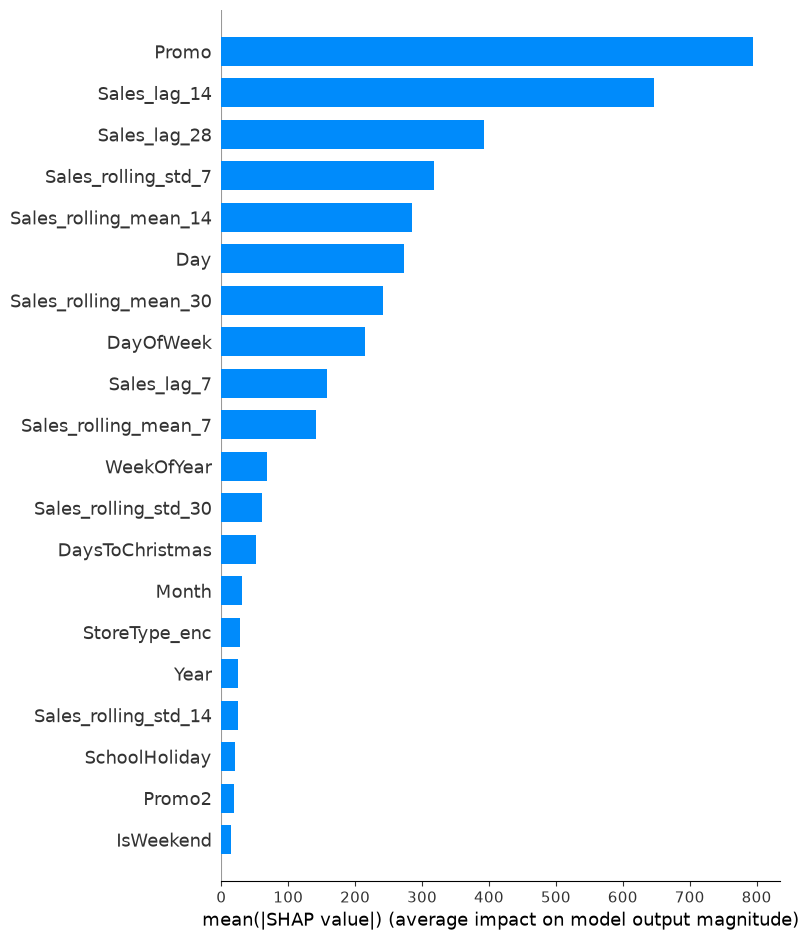

In [ ]:
import shap

explainer = shap.TreeExplainer(model)

# Hız için test setinden 2000 satırlık bir örnek alıyoruz, SHAP tüm veri üzerinde çok yavaş çalışır
X_test_sample = X_test.sample(2000, random_state=42)
shap_values = explainer.shap_values(X_test_sample)

shap.summary_plot(shap_values, X_test_sample, plot_type='bar')

In [ ]:
import joblib

test_eval = test_eval.copy()
test_eval['XGB_Pred'] = preds

test_eval.to_csv('../data/processed/test_eval_with_preds.csv', index=False)
joblib.dump(model, '../data/processed/xgb_model.pkl')
print('Kaydedildi:', test_eval.shape)
